In [1]:
import numpy as np
import pandas as pd
import sys
sys.path.insert(0, '.')

from Engine.TickData import TickData
from Engine.Backtester import Backtester


Loading tick data: ./Data/ESTick.txt
Loaded 23,033,489 ticks
Price range: 6751.50 - 7027.25

Analyzing 60 tick intervals (Williams fractals)...
Aggregated 23,033,489 ticks into 460,669 bars (50 tick)
Aggregated 23,033,489 ticks into 230,334 bars (100 tick)
Aggregated 23,033,489 ticks into 153,556 bars (150 tick)
Aggregated 23,033,489 ticks into 115,167 bars (200 tick)
Aggregated 23,033,489 ticks into 92,133 bars (250 tick)
Aggregated 23,033,489 ticks into 76,778 bars (300 tick)
Aggregated 23,033,489 ticks into 65,809 bars (350 tick)
Aggregated 23,033,489 ticks into 57,583 bars (400 tick)
Aggregated 23,033,489 ticks into 51,185 bars (450 tick)
Aggregated 23,033,489 ticks into 46,066 bars (500 tick)
Aggregated 23,033,489 ticks into 41,879 bars (550 tick)
Aggregated 23,033,489 ticks into 38,389 bars (600 tick)
Aggregated 23,033,489 ticks into 35,436 bars (650 tick)
Aggregated 23,033,489 ticks into 32,904 bars (700 tick)
Aggregated 23,033,489 ticks into 30,711 bars (750 tick)
Aggregated 2

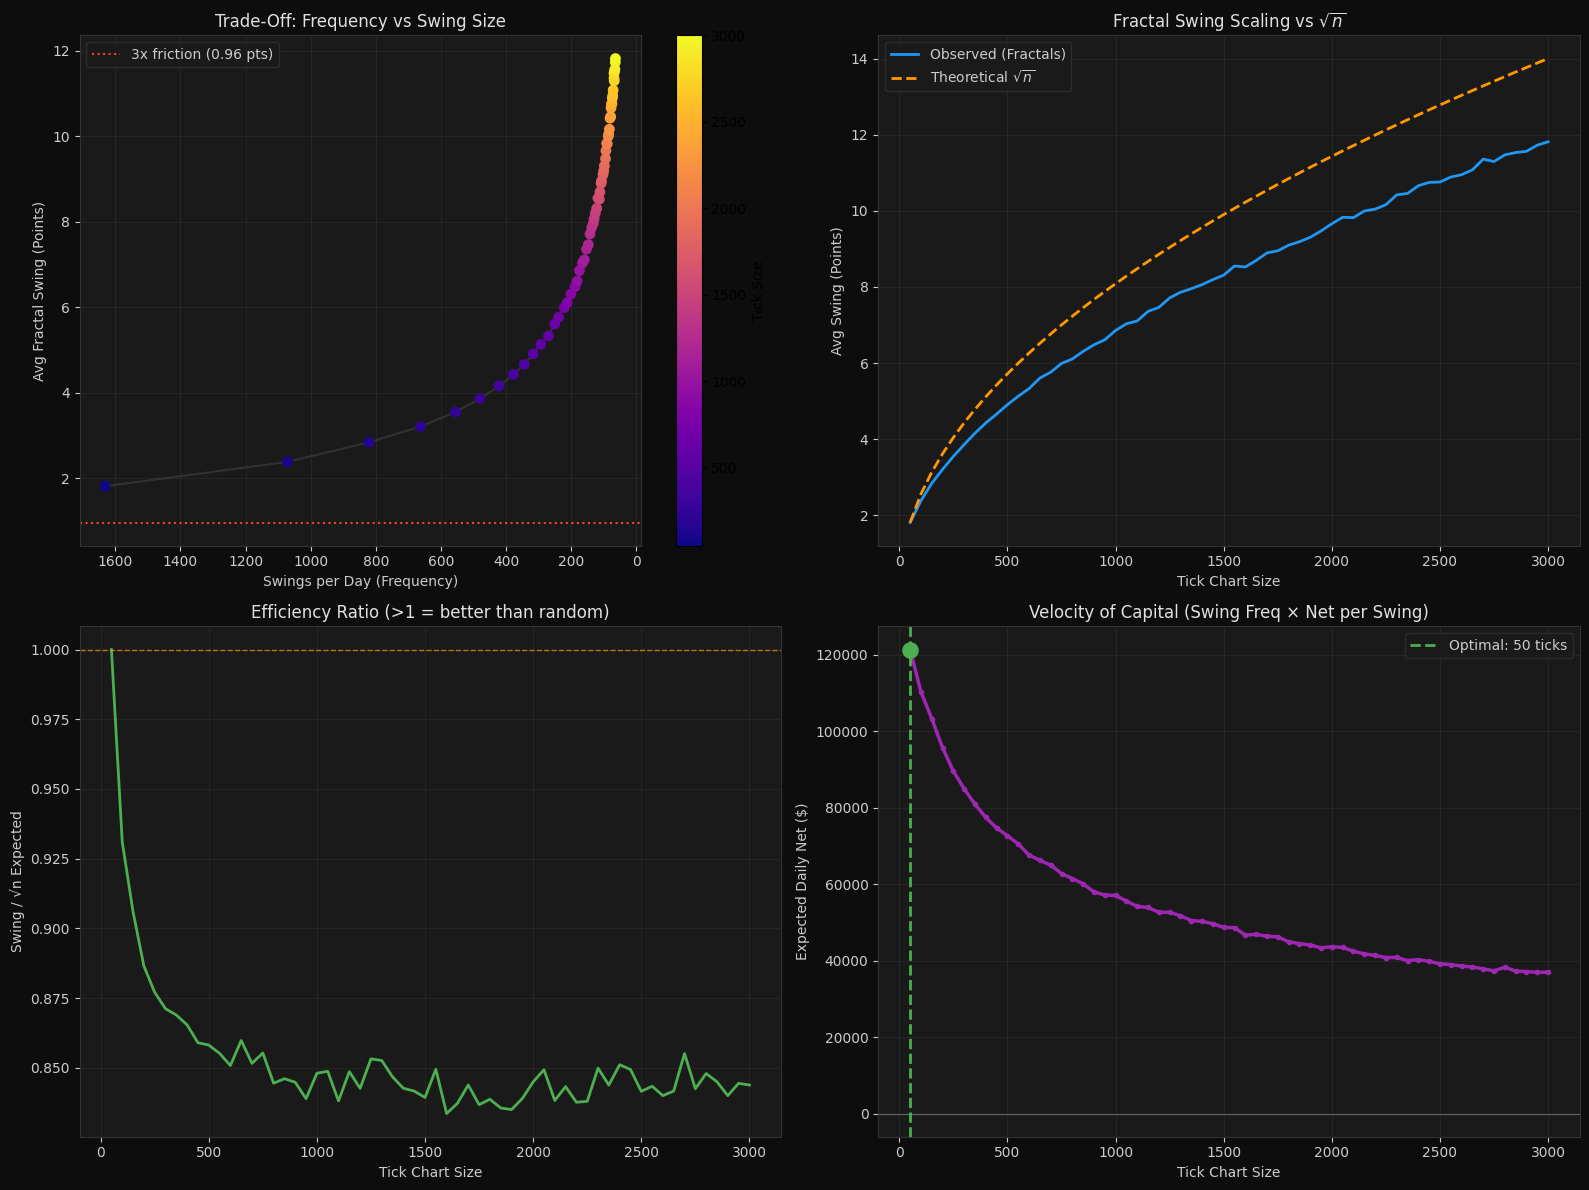


Optimal tick size by daily velocity: 50 ticks ($121,349/day)



Tick Size,Avg Swing (pts),Avg Swing ($),Swings/Day,Net/Swing ($),Daily Net ($)
50,1.808,$90.38,1631.4,$74.38,"$121,349"
100,2.380,$119.00,1071.0,$103.00,"$110,307"
150,2.836,$141.82,821.1,$125.82,"$103,312"
200,3.205,$160.25,663.1,$144.25,"$95,647"
250,3.545,$177.25,555.3,$161.25,"$89,550"
300,3.857,$192.87,480.1,$176.87,"$84,911"
350,4.156,$207.78,421.8,$191.78,"$80,886"
400,4.424,$221.22,377.3,$205.22,"$77,438"
450,4.658,$232.90,344.3,$216.90,"$74,672"
500,4.905,$245.26,316.8,$229.26,"$72,624"


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

td = TickData('./Data/ESTick.txt', timezone='America/Chicago')

# Parameters
start_tick = 50
end_tick = 3000
step_size = 50
tick_sizes = list(range(start_tick, end_tick + step_size, step_size))

# ES futures constants
friction_dollars = 16.00
point_value = 50.0


def williams_fractals(highs, lows, n=2):
    """Find Williams fractal swing points and return avg swing distance in points."""
    swing_prices = []
    swing_types = []  # 1 = swing high, -1 = swing low

    for i in range(n, len(highs) - n):
        # Swing high: high[i] > all n neighbors on both sides
        if all(highs[i] > highs[i - j] for j in range(1, n + 1)) and \
           all(highs[i] > highs[i + j] for j in range(1, n + 1)):
            swing_prices.append(highs[i])
            swing_types.append(1)
        # Swing low: low[i] < all n neighbors on both sides
        elif all(lows[i] < lows[i - j] for j in range(1, n + 1)) and \
             all(lows[i] < lows[i + j] for j in range(1, n + 1)):
            swing_prices.append(lows[i])
            swing_types.append(-1)

    if len(swing_prices) < 2:
        return 0.0, 0

    # Distance between consecutive fractal points
    swings = np.abs(np.diff(swing_prices))
    return swings.mean(), len(swings)


results = []
print(f"Analyzing {len(tick_sizes)} tick intervals (Williams fractals)...")

for size in tick_sizes:
    td.aggregate(method='tick', size=size)
    df = td.get_ohlc_dataframe()

    highs = df['High'].values
    lows = df['Low'].values

    avg_swing_pts, n_swings = williams_fractals(highs, lows, n=2)
    avg_swing_dollars = avg_swing_pts * point_value
    net_swing_dollars = avg_swing_dollars - friction_dollars

    total_days = len(np.unique(df.index.date))
    swings_per_day = n_swings / total_days if total_days > 0 else 0

    results.append({
        'tick_size': size,
        'avg_swing_pts': avg_swing_pts,
        'avg_swing_dollars': avg_swing_dollars,
        'net_per_swing': net_swing_dollars,
        'swings_per_day': swings_per_day,
        'daily_net': net_swing_dollars * swings_per_day,
        'n_swings': n_swings,
    })

results_df = pd.DataFrame(results)

# Theoretical sqrt(n) scaling (normalized to first valid point)
first_valid = results_df[results_df['avg_swing_pts'] > 0].iloc[0]
base_swing = first_valid['avg_swing_pts']
base_size = first_valid['tick_size']
theoretical_sqrt = base_swing * np.sqrt(results_df['tick_size'] / base_size)

# --- Plot ---
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.patch.set_facecolor('#0d0d0d')
for ax in axes.flat:
    ax.set_facecolor('#1a1a1a')
    ax.tick_params(colors='#ccc')
    ax.xaxis.label.set_color('#ccc')
    ax.yaxis.label.set_color('#ccc')
    ax.title.set_color('#e0e0e0')
    for spine in ax.spines.values():
        spine.set_color('#333')
    ax.grid(True, alpha=0.2, color='#555')

# 1) Frequency vs Avg Swing (the tradeoff curve)
ax = axes[0, 0]
sc = ax.scatter(results_df['swings_per_day'], results_df['avg_swing_pts'],
                c=results_df['tick_size'], cmap='plasma', s=60, edgecolor='none', zorder=5)
ax.plot(results_df['swings_per_day'], results_df['avg_swing_pts'],
        color='#555', linestyle='-', alpha=0.4, zorder=1)
min_viable_pts = (friction_dollars * 3) / point_value
ax.axhline(min_viable_pts, color='#f44336', linestyle=':', linewidth=1.5,
           label=f'3x friction ({min_viable_pts:.2f} pts)')
ax.set_xlabel('Swings per Day (Frequency)')
ax.set_ylabel('Avg Fractal Swing (Points)')
ax.set_title('Trade-Off: Frequency vs Swing Size')
ax.invert_xaxis()
ax.legend(facecolor='#1a1a1a', edgecolor='#333', labelcolor='#ccc')
plt.colorbar(sc, ax=ax, label='Tick Size')

# 2) Avg swing vs theoretical sqrt(n)
ax = axes[0, 1]
ax.plot(results_df['tick_size'], results_df['avg_swing_pts'],
        color='#2196F3', linewidth=2, label='Observed (Fractals)')
ax.plot(results_df['tick_size'], theoretical_sqrt,
        color='#FF9800', linewidth=2, linestyle='--', label=r'Theoretical $\sqrt{n}$')
ax.set_xlabel('Tick Chart Size')
ax.set_ylabel('Avg Swing (Points)')
ax.set_title(r'Fractal Swing Scaling vs $\sqrt{n}$')
ax.legend(facecolor='#1a1a1a', edgecolor='#333', labelcolor='#ccc')

# 3) Efficiency ratio: actual swing / sqrt(n) expected
ax = axes[1, 0]
efficiency = results_df['avg_swing_pts'] / theoretical_sqrt
ax.plot(results_df['tick_size'], efficiency, color='#4CAF50', linewidth=2)
ax.axhline(1.0, color='#FF9800', linestyle='--', linewidth=1, alpha=0.7)
ax.set_xlabel('Tick Chart Size')
ax.set_ylabel('Swing / √n Expected')
ax.set_title('Efficiency Ratio (>1 = better than random)')

# 4) Daily net profit (velocity of capital)
ax = axes[1, 1]
ax.plot(results_df['tick_size'], results_df['daily_net'],
        color='#9C27B0', linewidth=2.5, marker='o', markersize=3)
ax.axhline(0, color='#666', linewidth=0.8)
optimal_idx = results_df['daily_net'].idxmax()
opt_tick = results_df.loc[optimal_idx, 'tick_size']
opt_val = results_df.loc[optimal_idx, 'daily_net']
ax.axvline(opt_tick, color='#4CAF50', linestyle='--', linewidth=2,
           label=f'Optimal: {opt_tick} ticks')
ax.scatter(opt_tick, opt_val, color='#4CAF50', s=120, zorder=5)
ax.set_xlabel('Tick Chart Size')
ax.set_ylabel('Expected Daily Net ($)')
ax.set_title('Velocity of Capital (Swing Freq × Net per Swing)')
ax.legend(facecolor='#1a1a1a', edgecolor='#333', labelcolor='#ccc')

plt.tight_layout()
plt.show()

# Summary table
print(f"\n{'='*70}")
print(f"Optimal tick size by daily velocity: {opt_tick} ticks (${opt_val:,.0f}/day)")
print(f"{'='*70}\n")
top = results_df.nlargest(10, 'daily_net')[['tick_size', 'avg_swing_pts', 'avg_swing_dollars', 'swings_per_day', 'net_per_swing', 'daily_net']]
top.columns = ['Tick Size', 'Avg Swing (pts)', 'Avg Swing ($)', 'Swings/Day', 'Net/Swing ($)', 'Daily Net ($)']
display(top.style.format({
    'Avg Swing (pts)': '{:.3f}',
    'Avg Swing ($)': '${:.2f}',
    'Swings/Day': '{:.1f}',
    'Net/Swing ($)': '${:.2f}',
    'Daily Net ($)': '${:,.0f}',
}).hide(axis='index'))


Computing fractal distances for 30 tick sizes...
Aggregated 23,033,489 ticks into 230,334 bars (100 tick)
Aggregated 23,033,489 ticks into 115,167 bars (200 tick)
Aggregated 23,033,489 ticks into 76,778 bars (300 tick)
Aggregated 23,033,489 ticks into 57,583 bars (400 tick)
Aggregated 23,033,489 ticks into 46,066 bars (500 tick)
Aggregated 23,033,489 ticks into 38,389 bars (600 tick)
Aggregated 23,033,489 ticks into 32,904 bars (700 tick)
Aggregated 23,033,489 ticks into 28,791 bars (800 tick)
Aggregated 23,033,489 ticks into 25,592 bars (900 tick)
Aggregated 23,033,489 ticks into 23,033 bars (1000 tick)
Aggregated 23,033,489 ticks into 20,939 bars (1100 tick)
Aggregated 23,033,489 ticks into 19,194 bars (1200 tick)
Aggregated 23,033,489 ticks into 17,718 bars (1300 tick)
Aggregated 23,033,489 ticks into 16,452 bars (1400 tick)
Aggregated 23,033,489 ticks into 15,355 bars (1500 tick)
Aggregated 23,033,489 ticks into 14,395 bars (1600 tick)
Aggregated 23,033,489 ticks into 13,549 bars (

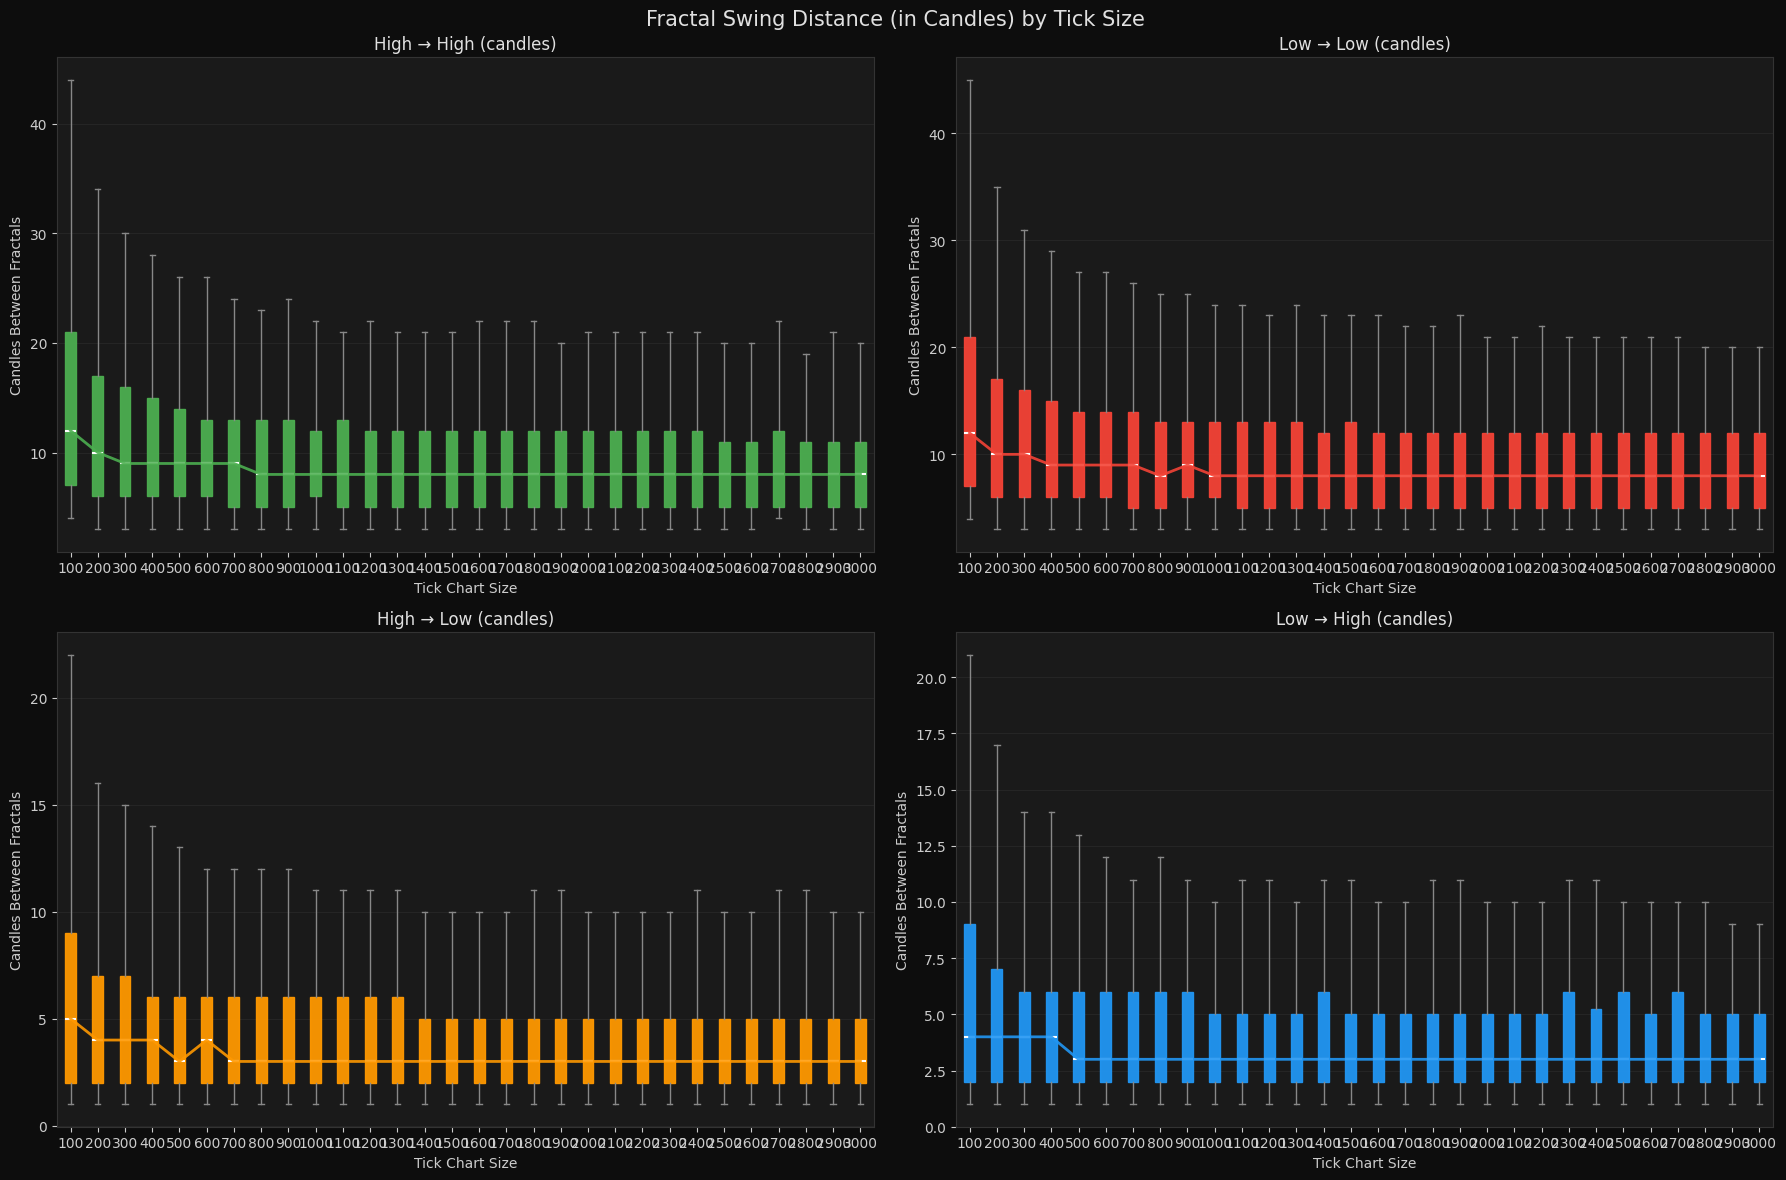

In [9]:
def williams_fractals_detailed(highs, lows, n=2):
    """Return bar indices and types for all fractal points."""
    indices = []
    types = []  # 1 = swing high, -1 = swing low

    for i in range(n, len(highs) - n):
        if all(highs[i] > highs[i - j] for j in range(1, n + 1)) and \
           all(highs[i] > highs[i + j] for j in range(1, n + 1)):
            indices.append(i)
            types.append(1)
        elif all(lows[i] < lows[i - j] for j in range(1, n + 1)) and \
             all(lows[i] < lows[i + j] for j in range(1, n + 1)):
            indices.append(i)
            types.append(-1)

    return np.array(indices), np.array(types)


# Subset of tick sizes for readability on box plots
tick_sizes_box = list(range(100, 3001, 100))

high_to_high_data = {}
low_to_low_data = {}
high_to_low_data = {}
low_to_high_data = {}

print(f"Computing fractal distances for {len(tick_sizes_box)} tick sizes...")

for size in tick_sizes_box:
    td.aggregate(method='tick', size=size)
    df = td.get_ohlc_dataframe()
    highs = df['High'].values
    lows = df['Low'].values

    frac_idx, frac_type = williams_fractals_detailed(highs, lows, n=2)
    if len(frac_idx) < 3:
        continue

    # Distances between consecutive same-type fractals
    high_indices = frac_idx[frac_type == 1]
    low_indices = frac_idx[frac_type == -1]

    if len(high_indices) > 1:
        high_to_high_data[size] = np.diff(high_indices)
    if len(low_indices) > 1:
        low_to_low_data[size] = np.diff(low_indices)

    # Distances between alternating types (high→low, low→high)
    h2l = []
    l2h = []
    for i in range(len(frac_idx) - 1):
        dist = frac_idx[i + 1] - frac_idx[i]
        if frac_type[i] == 1 and frac_type[i + 1] == -1:
            h2l.append(dist)
        elif frac_type[i] == -1 and frac_type[i + 1] == 1:
            l2h.append(dist)

    if h2l:
        high_to_low_data[size] = np.array(h2l)
    if l2h:
        low_to_high_data[size] = np.array(l2h)

# --- Plot ---
fig, axes = plt.subplots(2, 2, figsize=(18, 12))
fig.patch.set_facecolor('#0d0d0d')
fig.suptitle('Fractal Swing Distance (in Candles) by Tick Size', color='#e0e0e0', fontsize=15, y=0.98)

datasets = [
    (high_to_high_data, 'High → High (candles)', '#4CAF50'),
    (low_to_low_data, 'Low → Low (candles)', '#f44336'),
    (high_to_low_data, 'High → Low (candles)', '#FF9800'),
    (low_to_high_data, 'Low → High (candles)', '#2196F3'),
]

for ax, (data_dict, title, color) in zip(axes.flat, datasets):
    ax.set_facecolor('#1a1a1a')
    ax.tick_params(colors='#ccc')
    ax.xaxis.label.set_color('#ccc')
    ax.yaxis.label.set_color('#ccc')
    ax.title.set_color('#e0e0e0')
    for spine in ax.spines.values():
        spine.set_color('#333')
    ax.grid(True, alpha=0.2, color='#555', axis='y')

    sizes = sorted(data_dict.keys())
    box_data = [data_dict[s] for s in sizes]

    bp = ax.boxplot(box_data, positions=sizes, widths=40, patch_artist=True,
                    showfliers=False, whis=(5, 95),
                    medianprops=dict(color='white', linewidth=1.5),
                    whiskerprops=dict(color='#888'),
                    capprops=dict(color='#888'))

    for patch in bp['boxes']:
        patch.set_facecolor(color)
        patch.set_alpha(0.5)
        patch.set_edgecolor(color)

    # Overlay median line
    medians = [np.median(data_dict[s]) for s in sizes]
    ax.plot(sizes, medians, color=color, linewidth=2, alpha=0.9, zorder=5)

    ax.set_xlabel('Tick Chart Size')
    ax.set_ylabel('Candles Between Fractals')
    ax.set_title(title)
    ax.set_xlim(50, 3050)

plt.tight_layout()
plt.show()


In [35]:
import numpy as np
import pandas as pd
import sys
sys.path.insert(0, '.')

from Engine.TickData import TickData

# Load ES tick data and aggregate into 250-tick bars
td = TickData('./Data/ESTick.txt', timezone='America/Chicago')
td.aggregate(method='tick', size=200000)

tick_value = 12.50
contract_multiplier = 50
initial_equity = 100_000

ohlc = td.get_ohlc()
indices = td.get_indices()
timeframe = td.get_timeframe()
n_bars = len(ohlc)
close = ohlc[:, 3]

print(f'Bars: {n_bars:,}')
print(f'Date range: {indices[0]} to {indices[-1]}')


Loading tick data: ./Data/ESTick.txt
Loaded 23,033,489 ticks
Price range: 6751.50 - 7027.25

Aggregated 23,033,489 ticks into 115 bars (200000 tick)
Bars: 115
Date range: 2026-02-02 08:25:26.005800-06:00 to 2026-03-02 06:01:09.006560-06:00


In [2]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from scipy.special import gamma

def compute_ambe_hurst(X, delta, q=1, k=1):
    """
    Absolute Moments Based Estimator (AMBE) mirroring the provided paper logic.
    Computes rolling Hurst efficiently using a single lag and theoretical moments.
    """
    X = np.asarray(X)
    n = len(X)
    hurst_estimates = np.full(n, np.nan)
    
    # Normalization constant from the image
    K_k = (2**(k/2) * gamma((k+1)/2)) / np.sqrt(np.pi)
    
    # Loop over the rolling window
    for i in range(delta, n):
        window = X[i - delta : i + 1]
        
        # Compute k-th absolute moment of increments for the single lag 'q'
        diffs = np.abs(window[q:] - window[:-q])
        
        # Tick data can stall; avoid exact zeros to prevent log(0)
        if np.all(diffs == 0):
            hurst_estimates[i] = 0.5 # Default to random walk if completely flat
            continue
            
        S_k = np.mean(diffs**k)
        
        # Replicating the image's exact numerator/denominator math
        term_1 = np.sqrt(np.pi) * S_k
        term_2 = (2**(k/2)) * gamma((k+1)/2) * K_k
        numerator = np.log(term_1 / term_2)
        
        # Note: the image uses 'n' here, but in a rolling context, 
        # the effective sample size of the interval is 'delta'
        denominator = k * np.log((delta + 1) / q)
        
        H = - numerator / denominator
        hurst_estimates[i] = H
        
    return hurst_estimates

def ehlers_2_pole_supersmoother(data, period=10):
    """
    John Ehlers' 2-Pole SuperSmoother Filter.
    Effectively suppresses high-frequency noise/aliasing in the indicator.
    """
    a1 = np.exp(-np.pi * np.sqrt(2) / period)
    b1 = 2 * a1 * np.cos(np.pi * np.sqrt(2) / period)
    c2 = b1
    c3 = -a1**2
    c1 = 1 - c2 - c3
    
    smoothed = np.copy(data)
    
    for i in range(2, len(data)):
        if np.isnan(data[i]) or np.isnan(data[i-1]):
            continue
            
        # Handle initialization of prior values if they are nan
        prev1 = smoothed[i-1] if not np.isnan(smoothed[i-1]) else data[i]
        prev2 = smoothed[i-2] if not np.isnan(smoothed[i-2]) else data[i]
        
        term1 = c1 * (data[i] + data[i-1]) / 2.0
        smoothed[i] = term1 + c2 * prev1 + c3 * prev2
        
    return smoothed

# --- Execution ---
# Assuming 'close' is your raw tick price array
# close = np.random.randn(1000).cumsum() + 4000 # dummy data if needed

window_size = 30
lag_q = 1
moment_k = 2 # k=1 is standard for absolute moments, k=2 is variance

print(f"Calculating rolling AMBE Hurst Exponent (Window: {window_size}, q={lag_q}, k={moment_k})...")

# 1. Compute Raw Hurst
raw_hurst = compute_ambe_hurst(close, delta=window_size, q=lag_q, k=moment_k)

# 2. Shift to align signal (as in your original code)
# Using pandas just for the convenient shift method
shifted_hurst = pd.Series(raw_hurst).shift(-window_size).values

# 3. Apply Ehlers SuperSmoother to the shifted indicator
smoothed_hurst = ehlers_2_pole_supersmoother(shifted_hurst, period=10)

# Clean out bounds
smoothed_hurst = np.clip(smoothed_hurst, 0.0, 1.0)
x_axis = np.arange(len(close))

# --- Plotly Interactive Dashboard ---
fig = make_subplots(
    rows=2, cols=1, 
    shared_xaxes=True, 
    vertical_spacing=0.08,
    subplot_titles=("ES Futures Tick Price", f"AMBE Hurst w/ Ehlers Filter (Window: {window_size})"),
    row_heights=[0.6, 0.4]
)

# Top Plot: Close Price
fig.add_trace(
    go.Scatter(x=x_axis, y=close, mode='lines', name='Price', line=dict(color='#2c3e50', width=1.5)),
    row=1, col=1
)

# Bottom Plot: Raw Hurst (Faded)
fig.add_trace(
    go.Scatter(x=x_axis, y=shifted_hurst, mode='lines', name='Raw AMBE Hurst', 
               line=dict(color='rgba(142, 68, 173, 0.3)', width=1)),
    row=2, col=1
)

# Bottom Plot: Smoothed Hurst (Prominent)
fig.add_trace(
    go.Scatter(x=x_axis, y=smoothed_hurst, mode='lines', name='Smoothed Hurst', 
               line=dict(color='#8e44ad', width=2)),
    row=2, col=1
)

# Reference line at H = 0.5
fig.add_shape(
    type="line", x0=x_axis[0], y0=0.5, x1=x_axis[-1], y1=0.5,
    line=dict(color="black", width=1.5, dash="dash"), row=2, col=1
)

# Shading Zones
fig.add_hrect(y0=0.0, y1=0.5, fillcolor="rgba(39, 174, 96, 0.08)", layer="below", line_width=0, row=2, col=1)
fig.add_hrect(y0=0.5, y1=1.0, fillcolor="rgba(192, 57, 43, 0.08)", layer="below", line_width=0, row=2, col=1)

# Layout Configuration
fig.update_layout(
    height=800,
    showlegend=True,
    hovermode='x unified',
    template='plotly_white',
    margin=dict(l=60, r=30, t=50, b=50)
)

fig.update_yaxes(title_text="Price ($)", row=1, col=1)
fig.update_yaxes(title_text="Hurst (H)", range=[0, 1], row=2, col=1)
fig.update_xaxes(title_text="Tick", row=2, col=1)
fig.update_xaxes(matches='x')

fig.show()

Calculating rolling AMBE Hurst Exponent (Window: 30, q=1, k=2)...


NameError: name 'close' is not defined

In [ ]:
import numpy as np
import pandas as pd
import emd
import time
from IPython.display import clear_output
from Engine.TickData import TickData

# Load ES tick data and aggregate into 250-tick bars
td = TickData('./Data/ESTick.txt', timezone='America/Chicago')
td.aggregate(method='tick', size=1000)

tick_value = 12.50
contract_multiplier = 50
initial_equity = 100_000

ohlc = td.get_ohlc()
close = ohlc[:, 3]
df = pd.DataFrame({'Close': close})

MIN_WINDOW = 1000
PREDICTION_STEPS = 100
THRESHOLD = 0.5 

correct_predictions = 0
total_predictions = 0

print(f"Starting EMD Walk-Forward Analysis (using 'emd' library)...")
start_time = time.time()

for i in range(MIN_WINDOW, MIN_WINDOW + PREDICTION_STEPS):
    current_window = df['Close'].iloc[:i].values
    actual_next_close = df['Close'].iloc[i]
    
    # --- CORE EMD LOGIC (using 'emd' library) ---
    # The 'emd.sift.sift' function returns IMFs as (samples, imfs)
    # We take the first IMF (index 0)
    imfs = emd.sift.sift(current_window, max_imfs=3)
    current_imf1_state = imfs[-1, 0] 
    
    # Prediction logic
    actual_direction = "UP" if (actual_next_close - current_window[-1]) > 0 else "DOWN"
    prediction = "DOWN" if current_imf1_state > THRESHOLD else "UP"
    
    # Scoring
    if prediction == actual_direction:
        correct_predictions += 1
    total_predictions += 1
    
    if total_predictions % 5 == 0:
        clear_output(wait=True)
        print(f"Accuracy: {(correct_predictions / total_predictions) * 100:.2f}%")
        print(f"Last IMF1 State: {current_imf1_state:.3f}")

print(f"\nFinal Accuracy: {(correct_predictions / total_predictions) * 100:.2f}%")

Accuracy: 42.00%
Last IMF1 State: -0.886

Final Accuracy: 42.00%

Final Accuracy: 42.00%

Final Accuracy: 42.00%



>>> TESTING 250-TICK CHART <<<

Loading tick data: ./Data/ESTick.txt
Loaded 23,033,489 ticks
Price range: 6751.50 - 7027.25

Aggregated 23,033,489 ticks into 92,133 bars (250 tick)

--- Evaluating Critical Period: 750 ---

--- Evaluating Critical Period: 850 ---

--- Evaluating Critical Period: 950 ---

--- Evaluating Critical Period: 1050 ---

--- Evaluating Critical Period: 1150 ---

--- Evaluating Critical Period: 1250 ---

--- Evaluating Critical Period: 2000 ---


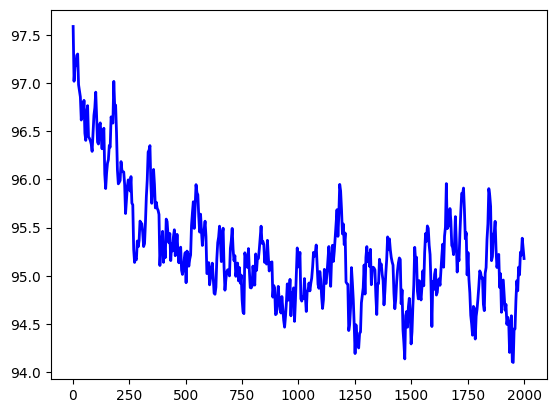

In [ ]:
import numpy as np
import pandas as pd
from Engine.TickData import TickData

def ultimate_smoother(prices, critical_period=250):
    prices = np.array(prices)
    n = len(prices)

    a1 = np.exp(-1.414 * np.pi / critical_period)
    c2 = 2.0 * a1 * np.cos(1.414 * np.pi / critical_period)
    c3 = -a1 * a1
    c1 = (1.0 + c2 - c3) / 4.0

    filt = np.zeros(n)

    for i in range(n):
        if i < 4:
            filt[i] = prices[i]
        else:
            filt[i] = (
                (1.0 - c1) * prices[i]
                + (2.0 * c1 - c2) * prices[i-1]
                - (c1 + c3) * prices[i-2]
                + c2 * filt[i-1]
                + c3 * filt[i-2]
            )
    return filt

def evaluate_smoother_ev(df, critical_period=50, friction_points=0.58):
    if isinstance(df, np.ndarray):
        highs = df[:, 1]
        lows = df[:, 2]
        closes = df[:, 3]
    else:
        highs = df[1].values
        lows = df[2].values
        closes = df[3].values

    n = len(closes)
    if n < critical_period + 10:
        print(f"Error: Not enough data. Found {n} bars.")
        return None

    filt = ultimate_smoother(closes, critical_period)

    current_state = None
    active_pivot_price = None
    run_violated = False
    entry_price = None
    
    # Trade tracking
    trades = []

    for i in range(1, n):
        # 1. Determine tick color
        if filt[i] > filt[i-1]:
            tick_state = 'green'
        elif filt[i] < filt[i-1]:
            tick_state = 'red'
        else:
            tick_state = current_state

        if tick_state is None:
            continue

        # 2. Did the state flip?
        if current_state != tick_state:
            
            # A. Close out the PREVIOUS trade if one was active
            if current_state is not None:
                exit_price = closes[i]
                
                if current_state == 'red':  # We were SHORT
                    risk = active_pivot_price - entry_price
                    if run_violated:
                        gross_pnl = -risk  # Stopped out at pivot
                    else:
                        gross_pnl = entry_price - exit_price  # Rode it to the flip
                        
                elif current_state == 'green':  # We were LONG
                    risk = entry_price - active_pivot_price
                    if run_violated:
                        gross_pnl = -risk  # Stopped out at pivot
                    else:
                        gross_pnl = exit_price - entry_price  # Rode it to the flip
                
                net_pnl = gross_pnl - friction_points
                
                trades.append({
                    'state': current_state,
                    'held': not run_violated,
                    'risk': risk,
                    'gross_pnl': gross_pnl,
                    'net_pnl': net_pnl
                })

            # B. Setup the NEW trade
            if tick_state == 'red':
                active_pivot_price = highs[i-1] + 0.75
                run_violated = False
                entry_price = closes[i]
                
            elif tick_state == 'green':
                active_pivot_price = lows[i-1] - 0.75
                run_violated = False
                entry_price = closes[i]

        # 3. Monitor for violations while in the current state
        if active_pivot_price is not None and not run_violated:
            if tick_state == 'red' and highs[i] > active_pivot_price:
                run_violated = True
            elif tick_state == 'green' and lows[i] < active_pivot_price:
                run_violated = True

        current_state = tick_state

    # 4. Process Results
    total_trades = len(trades)
    if total_trades == 0:
        return None

    held_trades = [t for t in trades if t['held']]
    violated_trades = [t for t in trades if not t['held']]
    
    hold_rate = (len(held_trades) / total_trades) * 100
    
    # avg_risk = np.mean([t['risk'] for t in trades])
    
    # # What was our average profit on the 90% of trades that held?
    # avg_gross_win = np.mean([t['gross_pnl'] for t in held_trades]) if held_trades else 0
    
    # # True Expected Value
    # avg_net_ev = np.mean([t['net_pnl'] for t in trades])
    # total_net_pnl = sum([t['net_pnl'] for t in trades])

    # print(f"--- Ultimate Smoother EV Analysis (Length {critical_period}) ---")
    # print(f"Total Trades Evaluated:    {total_trades}")
    # print(f"Pivot Hold Rate:           {len(held_trades)}/{total_trades} ({hold_rate:.2f}%)")
    # print(f"Average Risk (Stop Size):  {avg_risk:.2f} points")
    # print(f"Avg Gross PnL (Winning):   {avg_gross_win:.2f} points (The reward for a held pivot)")
    # print(f"---")
    # print(f"Friction Penalty/Trade:   -{friction_points:.2f} points")
    # print(f"Average NET EV per trade:  {avg_net_ev:.2f} points")
    # print(f"Cumulative Net PnL:        {total_net_pnl:.2f} points")

    return hold_rate
# ==========================================
# Execution Block
# ==========================================
if __name__ == "__main__":
    # Test 250 Tick
    print("\n>>> TESTING 250-TICK CHART <<<")
    td_250 = TickData('./Data/ESTick.txt', timezone='America/Chicago')
    df_250 = td_250.aggregate(method='tick', size=250).get_ohlc()
    x = np.linspace(1, 2000, num=500)
    y = []
    for i in x:
        i = int(i)
        if i % 50 == 0:
            print(f"\n--- Evaluating Critical Period: {i} ---")
        hold_rate = evaluate_smoother_ev(df_250, critical_period=i)
        y.append(hold_rate)

    import matplotlib.pyplot as plt
    plt.plot(x, y, color='blue', linewidth=2)
    plt.show()

    # Test 1000 Tick
    # print("\n>>> TESTING 1000-TICK CHART <<<")
    # td_1000 = TickData('./Data/ESTick.txt', timezone='America/Chicago')
    # df_1000 = td_1000.aggregate(method='tick', size=1000).get_ohlc()
    # evaluate_smoother_ev(df_1000, critical_period=250)

<>:51: SyntaxWarning:

invalid escape sequence '\m'

<>:51: SyntaxWarning:

invalid escape sequence '\s'

<>:51: SyntaxWarning:

invalid escape sequence '\m'

<>:51: SyntaxWarning:

invalid escape sequence '\s'

C:\Users\ryany\AppData\Local\Temp\ipykernel_26996\3393239526.py:51: SyntaxWarning:

invalid escape sequence '\m'

C:\Users\ryany\AppData\Local\Temp\ipykernel_26996\3393239526.py:51: SyntaxWarning:

invalid escape sequence '\s'




Loading tick data: ./Data/ESTick.txt
Loaded 23,033,489 ticks
Price range: 6751.50 - 7027.25

Aggregated 23,033,489 ticks into 92,133 bars (250 tick)

Loading tick data: ./Data/ESTick.txt
Loaded 23,033,489 ticks
Price range: 6751.50 - 7027.25

Aggregated 23,033,489 ticks into 92,133 bars (250 tick)


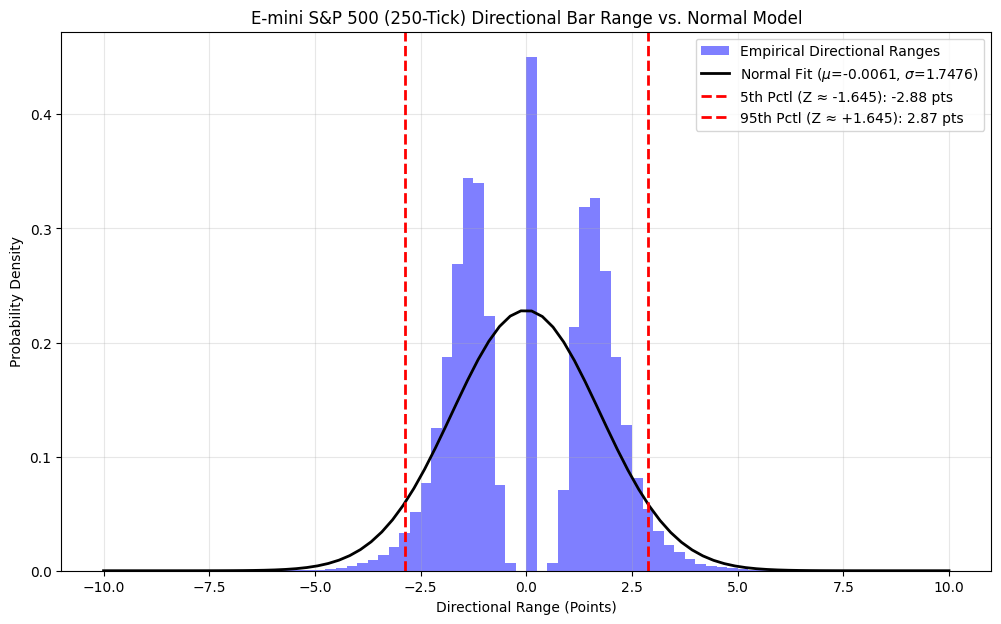

In [35]:
import numpy as np
import pandas as pd
from Engine.TickData import TickData
import matplotlib.pyplot as plt
td_250 = TickData('./Data/ESTick.txt', timezone='America/Chicago')
df_250 = td_250.aggregate(method='tick', size=250).get_ohlc()
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
# Assuming TickData is loaded as in your snippet
from Engine.TickData import TickData

td_250 = TickData('./Data/ESTick.txt', timezone='America/Chicago')
df_250 = td_250.aggregate(method='tick', size=250).get_ohlc()

# Extract columns (Assuming Open=0, High=1, Low=2, Close=3)
opens = df_250[:, 0]
highs = df_250[:, 1]
lows = df_250[:, 2]
closes = df_250[:, 3]

# 1. Calculate the absolute size of the candle
candle_size = highs - lows

# 2. Determine the polarity (Bullish = +1, Bearish = -1, Doji = 0)
# np.sign returns -1 if x < 0, 0 if x==0, 1 if x > 0
polarity = np.sign(closes - opens)

# 3. Calculate Directional Excursion
directional_ranges = candle_size * polarity

# --- Statistical Fitting ---

# Fit a normal distribution to the directional ranges
mu, std = norm.fit(directional_ranges)

# Calculate the 90% Confidence Interval (5th and 95th percentiles)
ci_90_lower = norm.ppf(0.05, loc=mu, scale=std)
ci_90_upper = norm.ppf(0.95, loc=mu, scale=std)

# --- Plotting ---
plt.figure(figsize=(12, 7))

# Plot the empirical histogram of our new metric
count, bins, ignored = plt.hist(directional_ranges, bins=80, density=True, alpha=0.5, color='b', range=(-10, 10), label='Empirical Directional Ranges')

# Plot the theoretical PDF
x = np.linspace(-10, 10, 80)
pdf = norm.pdf(x, loc=mu, scale=std)
plt.plot(x, pdf, 'k-', linewidth=2, label=f'Normal Fit ($\mu$={mu:.4f}, $\sigma$={std:.4f})')

# Overlay the Confidence Intervals
plt.axvline(ci_90_lower, color='r', linestyle='dashed', linewidth=2, label=f'5th Pctl (Z ≈ -1.645): {ci_90_lower:.2f} pts')
plt.axvline(ci_90_upper, color='r', linestyle='dashed', linewidth=2, label=f'95th Pctl (Z ≈ +1.645): {ci_90_upper:.2f} pts')

# Formatting
plt.title("E-mini S&P 500 (250-Tick) Directional Bar Range vs. Normal Model")
plt.xlabel("Directional Range (Points)")
plt.ylabel("Probability Density")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [11]:
import numpy as np
import pandas as pd

# IMPORTANT: Make sure to import your Backtester class alongside TickData
from Engine.TickData import TickData
from Engine.Backtester import Backtester

def ultimate_smoother(prices, critical_period=250):
    prices = np.array(prices)
    n = len(prices)
    a1 = np.exp(-1.414 * np.pi / critical_period)
    c2 = 2.0 * a1 * np.cos(1.414 * np.pi / critical_period)
    c3 = -a1 * a1
    c1 = (1.0 + c2 - c3) / 4.0
    filt = np.zeros(n)
    for i in range(n):
        if i < 4:
            filt[i] = prices[i]
        else:
            filt[i] = ((1.0 - c1) * prices[i] + (2.0 * c1 - c2) * prices[i-1] 
                       - (c1 + c3) * prices[i-2] + c2 * filt[i-1] + c3 * filt[i-2])
    return filt

# ==========================================
# 1. Load and Format Data
# ==========================================
print("Loading data...")
td = TickData('./Data/ESTick.txt', timezone='America/Chicago')
df = td.aggregate(method='tick', size=250)

ohlc = df.get_ohlc()  # Returns a numpy array of shape (n_bars, 4) with [Open, High, Low, Close]
indices = df.get_indices()  # Returns a numpy array of datetime indices corresponding to each bar

n_bars = len(ohlc)
closes = ohlc[:, 3]

# ==========================================
# 2. Define Backtester Parameters (ES Specs)
# ==========================================
timeframe = '1min'
tick_value = 12.5
contract_multiplier = 50.0  # $50 per point in the ES
initial_equity = 100000.0

# ==========================================
# 3. Strategy Configuration
# ==========================================
critical_period = 250
rr_ratio = 0.1  # 1:1 Risk/Reward

filt = ultimate_smoother(closes, critical_period=critical_period)

signal = np.zeros(n_bars)
position = 0
entry_price = 0.0
sl_price = 0.0
tp_price = 0.0
current_state = None

# ==========================================
# 4. Generate Signals
# ==========================================
print("Generating signals...")
for i in range(1, n_bars):
    close_px = ohlc[i, 3]
    high_px = ohlc[i, 1]
    low_px = ohlc[i, 2]

    # A. Determine Smoother Color
    if filt[i] > filt[i-1]:
        tick_state = 'green'
    elif filt[i] < filt[i-1]:
        tick_state = 'red'
    else:
        tick_state = current_state
        
    if tick_state is None:
        current_state = tick_state
        continue

    # B. Manage Active Positions (Check TP / SL first)
    if position != 0:
        hit_tp = False
        hit_sl = False

        if position == 1: # LONG
            hit_tp = high_px >= tp_price
            hit_sl = low_px <= sl_price
        else:             # SHORT
            hit_tp = low_px <= tp_price
            hit_sl = high_px >= sl_price

        # Exit position if either boundary is hit
        if hit_tp or hit_sl:
            position = 0

    # C. Look for New Entries (Only if flat and color just flipped)
    if position == 0 and current_state != tick_state and current_state is not None:
        
        if tick_state == 'red':
            # Flipped Down -> Go SHORT. Pivot is the previous Green High
            pivot_high = ohlc[i-1, 1]
            risk = pivot_high - close_px
            
            # Ensure risk is a valid positive number
            if risk > 0:
                position = -1
                entry_price = close_px
                sl_price = pivot_high
                tp_price = close_px - (risk * rr_ratio)
                
        elif tick_state == 'green':
            # Flipped Up -> Go LONG. Pivot is the previous Red Low
            pivot_low = ohlc[i-1, 2]
            risk = close_px - pivot_low
            
            if risk > 0:
                position = 1
                entry_price = close_px
                sl_price = pivot_low
                tp_price = close_px + (risk * rr_ratio)

    # D. Record the active state for the backtester
    signal[i] = position
    current_state = tick_state

# --- Print Quick Diagnostics ---
entries = np.diff(signal)
long_entries = int(np.sum((entries > 0) & (signal[1:] == 1)))
short_entries = int(np.sum((entries < 0) & (signal[1:] == -1)))

print(f"\n--- Strategy Triggered ---")
print(f"Long Trades:  {long_entries}")
print(f"Short Trades: {short_entries}")
print(f"Total Trades: {long_entries + short_entries}\n")

# ==========================================
# 5. Execute Backtester
# ==========================================
print("Running Backtest...")
bt = Backtester(
    ohlc=ohlc,
    indicies=indices,           # Notice the spelling precisely matches your class arguments
    signal=signal,
    timeframe=timeframe,
    tick_value=tick_value,
    contract_multiplier=contract_multiplier,
    initial_equity=initial_equity,
    slippage_ticks=0,         # 0.5 ticks ($6.25) slippage per trade
    commission=3.5,             # $3.50 commission per trade
)

bt.full_backtest()
print(bt)
from Engine.Report import generate_report
generate_report(bt, 'backtest_report.html', open_browser=True)

Loading data...

Loading tick data: ./Data/ESTick.txt
Loaded 23,033,489 ticks
Price range: 6751.50 - 7027.25

Aggregated 23,033,489 ticks into 92,133 bars (250 tick)
Generating signals...

--- Strategy Triggered ---
Long Trades:  2209
Short Trades: 2192
Total Trades: 4401

Running Backtest...

        Backtest Results from 2026-02-01 23:00:00.003520-06:00 to 2026-03-02 07:30:20.001880-06:00 (28 days 08:30:19.998360)
        Equity:     $100,000.00 -> $82,721.50
        Buy & Hold: $100,000.00 -> $93,162.50
        Buy & Hold Return (%): -6.84%
        Strategy Return (%):   -17.28%

        Total Trades:     4401.00
        Win Rate:         47.81%
        95% CI:           46.33% - 49.28%
        Avg. Win:         $39.11
        Avg. Loss:        $-43.34
        Ratio Win/Loss:   0.90
        Expected Value:   $-3.93

        Largest Win:      $244.75
        Largest Loss:     $-416.00
        Max Consec. Wins: 14
        Max Consec. Loss: 11

        Max Drawdown from 2026-02-02 14:4

'C:\\Users\\ryany\\OneDrive\\Desktop\\Futures-PC\\MacLink\\RugbeatunoBacktestingSuite\\backtest_report.html'

In [19]:
import numpy as np
import pandas as pd
from Engine.TickData import TickData

# ==========================================
# 1. Load and Clean Data
# ==========================================
td = TickData('./Data/ESTick.txt', timezone='America/Chicago')
df = td.aggregate(method='tick', size=250) 
df = df.get_ohlc()

# Extract close prices as a clean 1D numpy array
prices = df[:, 3]
highs = df[:, 1]
lows = df[:, 2]

# ==========================================
# 2. Define Indicators
# ==========================================
def ultimate_smoother(prices, critical_period=50):
    n = len(prices)
    a1 = np.exp(-1.414 * np.pi / critical_period)
    c2 = 2.0 * a1 * np.cos(1.414 * np.pi / critical_period)
    c3 = -a1 * a1
    c1 = (1.0 + c2 - c3) / 4.0

    filt = np.zeros(n)
    for i in range(n):
        if i < 4:
            filt[i] = prices[i]
        else:
            filt[i] = (
                (1.0 - c1) * prices[i]
                + (2.0 * c1 - c2) * prices[i-1]
                - (c1 + c3) * prices[i-2]
                + c2 * filt[i-1]
                + c3 * filt[i-2]
            )
    return filt

def frama(prices, highs, lows, N=16):
    """
    John Ehlers' Fractal Adaptive Moving Average (FRAMA)
    N must be an even number for the window splits.
    """
    n = len(prices)
    filt = np.zeros(n)
    half_N = int(N / 2)
    
    for i in range(n):
        if i < N:
            filt[i] = prices[i]
        else:
            # Window 1 (first half of the lookback interval)
            high1 = np.max(highs[i - N + 1 : i - half_N + 1])
            low1 = np.min(lows[i - N + 1 : i - half_N + 1])
            N1 = (high1 - low1) / half_N
            
            # Window 2 (second half of the lookback interval)
            high2 = np.max(highs[i - half_N + 1 : i + 1])
            low2 = np.min(lows[i - half_N + 1 : i + 1])
            N2 = (high2 - low2) / half_N
            
            # Window 3 (entire lookback interval)
            high3 = np.max(highs[i - N + 1 : i + 1])
            low3 = np.min(lows[i - N + 1 : i + 1])
            N3 = (high3 - low3) / N
            
            # Calculate Fractal Dimension (D)
            D = 0.0
            if N1 > 0 and N2 > 0 and N3 > 0:
                D = (np.log(N1 + N2) - np.log(N3)) / np.log(2.0)
            
            # Enforce bounds on Fractal Dimension
            D = max(1.0, min(2.0, D))
            
            # Calculate Exponential Smoothing Factor (alpha)
            # Ehlers uses an exponential scaling argument wrapper
            alpha = np.exp(-4.6 * (D - 1.0))
            alpha = max(0.01, min(1.0, alpha)) # Clamp boundaries
            
            filt[i] = alpha * prices[i] + (1.0 - alpha) * filt[i-1]
            
    return filt

# ==========================================
# 3. Compute and Calculate Correlation
# ==========================================
# Run indicators (matching typical lookback periods for comparison)
us_line = ultimate_smoother(prices, critical_period=50)
frama_line = frama(prices, highs, lows, N=12)

# Slice array to discard the initialization period warm-up window
warmup = 50
us_clean = us_line[warmup:]
frama_clean = frama_line[warmup:]

# Compute Pearson Correlation Matrix
# Compute correlation on the rate of change instead of raw values
us_change = np.diff(us_clean)
frama_change = np.diff(frama_clean)

true_correlation = np.corrcoef(us_change, frama_change)[0, 1]

print("=== STATISTICAL COMPARISON ===")
print(f"Data Points Evaluated: {len(us_clean)}")
print(f"True Structural Correlation: {true_correlation:.4f}")

print("==============================")


Loading tick data: ./Data/ESTick.txt
Loaded 23,033,489 ticks
Price range: 6751.50 - 7027.25

Aggregated 23,033,489 ticks into 92,133 bars (250 tick)
=== STATISTICAL COMPARISON ===
Data Points Evaluated: 92083
True Structural Correlation: 0.6563
